In [29]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

In [30]:
df = pd.read_csv("housePrice.csv")
df.head()

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price_USD
0,63,1,True,True,True,Shahran,1850000000,61666.67
1,60,1,True,True,True,Shahran,1850000000,61666.67
2,79,2,True,True,True,Pardis,550000000,18333.33
3,95,2,True,True,True,Shahrake Qods,902500000,30083.33
4,123,2,True,True,True,Shahrake Gharb,7000000000,233333.33


In [31]:
df.describe()

,Area,Room,Price,Price_USD
count,3473.000000,3473.000000,3.473000e+03,3.473000e+03
mean,106.774547,2.079758,5.354621e+09,1.784874e+05
std,69.365567,0.758764,8.104058e+09,2.701353e+05
min,30.000000,0.000000,3.600000e+06,1.200000e+02
25%,69.000000,2.000000,1.415000e+09,4.716667e+04
50%,90.000000,2.000000,2.880000e+09,9.600000e+04
75%,120.000000,2.000000,6.000000e+09,2.000000e+05
max,929.000000,5.000000,9.240000e+10,3.080000e+06


In [95]:
cdf = df[["Area", "Room", "Price", "Price_USD"]]
cdf.head()


,Area,Room,Price,Price_USD
0,63,1,1850000000,61666.67
1,60,1,1850000000,61666.67
2,79,2,550000000,18333.33
3,95,2,902500000,30083.33
4,123,2,7000000000,233333.33


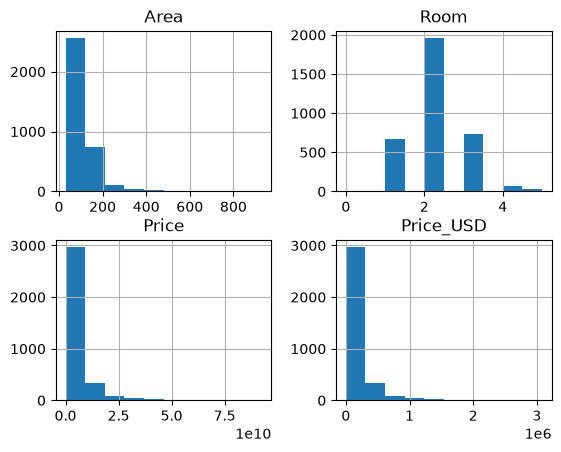

In [96]:
cdf.hist()
plt.show()

In [94]:
Q1, Q3 = df["Area"].quantile([0.25, 0.75])
Upper_lim = Q3 + 1.5*(Q3 - Q1)
dataset = df[df['Area'] <= Upper_lim]
dataset.head()

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price_USD
0,63,1,True,True,True,Shahran,1850000000,61666.67
1,60,1,True,True,True,Shahran,1850000000,61666.67
2,79,2,True,True,True,Pardis,550000000,18333.33
3,95,2,True,True,True,Shahrake Qods,902500000,30083.33
4,123,2,True,True,True,Shahrake Gharb,7000000000,233333.33


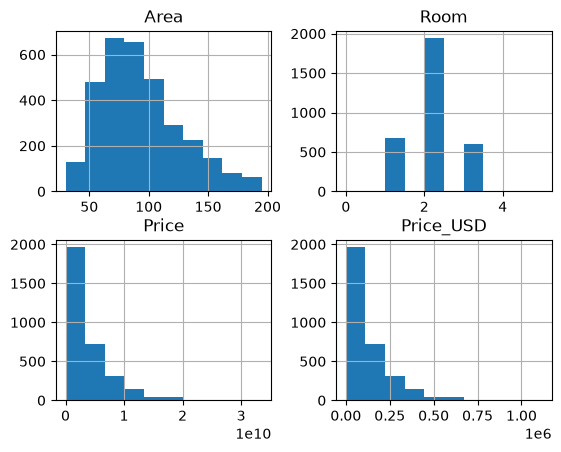

In [97]:
dataset.hist()
plt.show()

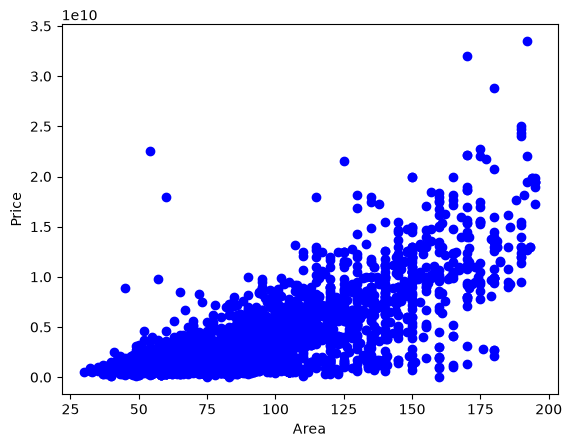

In [98]:
plt.scatter(dataset.Area, dataset.Price, color='blue')
plt.xlabel("Area")
plt.ylabel("Price")
plt.show()

In [99]:
Data = dataset[["Area", "Price"]]
Data.head()

,Area,Price
0,63,1850000000
1,60,1850000000
2,79,550000000
3,95,902500000
4,123,7000000000


In [101]:
Xdata, Ydata = (Data["Area"].values, Data["Price"].values)
Xnorm = Xdata/max(Xdata)
Ynorm = Ydata/max(Ydata)
mask = np.random.rand(len(dataset)) < 0.8

Xtrain = Xnorm[mask]
Ytrain = Ynorm[mask]

Xtest  = Xnorm[~mask]
Ytest  = Ynorm[~mask]

In [102]:
def Parabola (x: np.ndarray, a: float, b: float, c: float) -> np.ndarray:
    y = (a * np.power(x, b)) + c
    return y

In [103]:
from scipy.optimize import curve_fit

popt, pcov = curve_fit(Parabola, Xtrain, Ytrain)

popt


array([0.47745794, 2.64522545, 0.0289541 ])

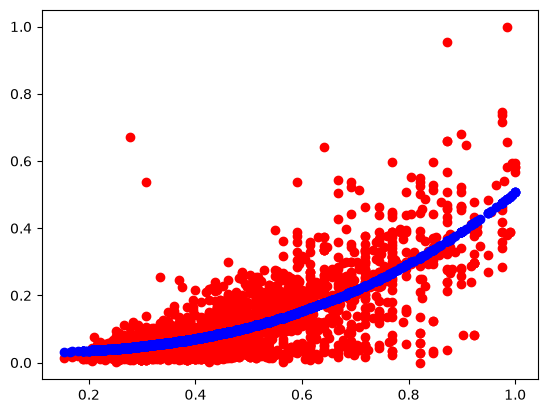

In [105]:
plt.scatter(Xtrain, Ytrain, color='red')
plt.scatter(Xtrain, Parabola(Xtrain, *popt), color='blue')
plt.show()

In [106]:
from sklearn.metrics import r2_score

Ypredict = Parabola(Xtest, *popt)

print("Mean absolute error: %.2f" % np.mean(np.absolute(Ytest - Ypredict)))
print("Residual sum of squares (MSE): %.2f" % np.mean((Ytest - Ypredict) ** 2))
print("R2-score: %.2f" % r2_score(Ytest , Ypredict))

Mean absolute error: 0.05
Residual sum of squares (MSE): 0.01
R2-score: 0.62
